In [91]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pydhn
from pydhn.fluids import Fluid
from pydhn.soils import Soil
from pydhn.solving import SimpleStep, Scheduler

In [92]:
# ---------------------------------------------------------------------------
# Simulation parameters
# ---------------------------------------------------------------------------
STEPSIZE       = 600          # time step [s]  (10 min)
NUM_SIM_STEPS  = 1008         # 7 days × 144 steps/day
T_AMBIENT_C    = 10.0         # ambient / ground temperature [°C]

In [93]:
# ---------------------------------------------------------------------------
# File paths
# ---------------------------------------------------------------------------
PIPES_FILE = "pipes.csv"
NODES_FILE = "nodes.csv"
DEMAND_PROFILE_FILE = "../../data/demand_profile.csv"

# ---------------------------------------------------------------------------
# Load input data
# ---------------------------------------------------------------------------
pipe_data = pd.read_csv(PIPES_FILE)
node_data = pd.read_csv(NODES_FILE)
demand_profile_data = pd.read_csv(DEMAND_PROFILE_FILE)
demand_profile_data = demand_profile_data[:NUM_SIM_STEPS]

time_sim   = demand_profile_data["timestep"].values * STEPSIZE  # [s]
heat_demand = demand_profile_data["Q_W"] * (STEPSIZE / 3600)    # [Wh]
MDOT_BYPASS_KGS = 1.77 / 3600                                   # [kg/s], bypass mass flow

print(f"Loaded topological data from {PIPES_FILE} "
      f"--- dynamic simulation of {len(demand_profile_data)} time steps.")

Loaded topological data from pipes.csv --- dynamic simulation of 1008 time steps.


In [94]:
# ---------------------------------------------------------------------------
# Fluid and soil
# ---------------------------------------------------------------------------
# Properties taken from first pipe row (homogeneous network assumption)
p0 = pipe_data.iloc[0]

fluid = Fluid(
    name       = "Water",
    isconstant = True,
    cp         = p0["fluid_cp_JkgK"],
    mu         = p0["fluid_mu_Pas"],
    rho        = p0["fluid_rho_kgm3"],
    k          = p0["fluid_lambda_WmK"],
)

soil = Soil(
    k    = p0["soil_lambda_WmK"],
    temp = p0["T_ground_degC"],
)

# ---------------------------------------------------------------------------
# Built network
# ---------------------------------------------------------------------------
net = pydhn.Network()

# Add nodes
for _, row in node_data.iterrows():
    name      = row["node_id"]
    node_type = row["node_type"]
    X, Y      = row["x_m"], row["y_m"]

    name_s = f"{name}_s"
    name_r = f"{name}_r"

    net.add_node(name=name_s, x=X, y=-Y)
    net.add_node(name=name_r, x=X, y=-Y)

    # Add substations
    if node_type == "substation":
        delta_t = float(row["delta_T_nom_K"])
        net.add_consumer(
            name              = name,
            start_node        = name_s,
            end_node          = name_r,
            control_type      = "mass_flow",
            setpoint_type_hyd = "mass_flow",
            setpoint_value_hyd = MDOT_BYPASS_KGS,   # kg/s, initial value
            setpoint_type_hx  = "delta_q",
            setpoint_value_hx = 0.0,                # Wh, initial value
            design_delta_t    = delta_t,
            t_out_min_hx      = 20,
            stepsize          = STEPSIZE,
        )

    # Add central generator
    elif node_type == "source":
        t_supply = float(row["T_supply_set_degC"])
        net.add_producer(
            name                = name,
            start_node          = name_r,
            end_node            = name_s,
            setpoint_type_hx    = "t_out",
            setpoint_value_hx   = t_supply,
            stepsize            = STEPSIZE,
        )

# Add pipes
for _, row in pipe_data.iterrows():
    name = row["pipe_id"]
    frm  = row["from_node"]
    to   = row["to_node"]

    common = dict(
        # --- geometry ---
        diameter                = row["d_inner_m"],                 # carrier pipe inner diameter [m]
        length                  = row["length_m"],                  # pipe length [m]
        internal_pipe_thickness = row["wall_m"],                    # steel wall thickness [m]
        insulation_thickness    = row["insulation_thickness_m"],    # PUR foam thickness [m]
        casing_thickness        = row["casing_thickness_m"],        # HDPE casing wall thickness [m]
        # --- hydraulic ---
        roughness               = row["roughness_mm"],              # absolute roughness [mm]
        # --- thermal: insulation ---
        k_insulation            = row["PUR_lambda_WmK"],            # PUR thermal conductivity [W/(m·K)]
        # --- thermal: carrier pipe ---
        k_internal_pipe         = row["steel_lambda_WmK"],          # steel thermal conductivity [W/(m·K)]
        rho_wall                = row["steel_rho_kgm3"],            # steel density [kg/m³]
        cp_wall                 = row["steel_cp_JkgK"],             # steel specific heat [J/(kg·K)]
        # --- thermal: casing ---
        k_casing                = row["HDPE_lambda_WmK"],           # HDPE thermal conductivity [W/(m·K)]
        # --- burial ---
        depth                   = row["burial_depth_m"],            # burial depth [m]
        h_ext                   = row["h_ext_Wm2K"],                # external heat transfer coeff. [W/(m²·K)]
        # --- simulation ---
        stepsize                = STEPSIZE,                         # time step [s]
    )

    # Supply pipe
    net.add_lagrangian_pipe(
        name       = f"{name}_s",
        start_node = f"{frm}_s",
        end_node   = f"{to}_s",
        line       = "supply",
        **common,
    )

    # Return pipe
    net.add_lagrangian_pipe(
        name       = f"{name}_r",
        start_node = f"{to}_r",
        end_node   = f"{frm}_r",
        line       = "return",
        **common,
    )

print("--- Network setup complete. ---")

--- Network setup complete. ---


In [95]:
# ---------------------------------------------------------------------------
# Schedules
# ---------------------------------------------------------------------------
consumer_demand_schedule   = pd.DataFrame()
consumer_massflow_schedule = pd.DataFrame()
consumer_names = []

for i in node_data.index:
    row       = node_data.loc[i]
    name      = row["node_id"]
    node_type = row["node_type"]

    if node_type == "substation":
        consumer_names.append(name)
        delta_t = float(row["delta_T_nom_K"])

        q_w  = demand_profile_data["Q_W"].values          # [W]
        q_wh = heat_demand

        mdot = np.where(
            q_w == 0,
            MDOT_BYPASS_KGS,                              # bypass [kg/s]
            q_w / (fluid.cp * delta_t)                    # nominal mass flow [kg/s]
        )

        # Energia: reale quando Q>0, zero quando Q=0
        q_schedule = np.where(q_w == 0, 0.0, -q_wh)      # [Wh]

        consumer_massflow_schedule[name] = mdot
        consumer_demand_schedule[name]   = q_schedule

consumer_massflow_schedule = consumer_massflow_schedule[consumer_names]
consumer_demand_schedule   = consumer_demand_schedule[consumer_names]

schedules = {
    "setpoint_value_hyd": consumer_massflow_schedule,   # [kg/s]
    "setpoint_value_hx":  consumer_demand_schedule,     # [Wh]
}

print(f"Schedules built: {len(consumer_names)} consumers × {NUM_SIM_STEPS} steps.")

Schedules built: 10 consumers × 1008 steps.


In [96]:
# ---------------------------------------------------------------------------
# Pre-heating (network initialization)
# ---------------------------------------------------------------------------
print("--- Initializing Network (Pre-heating for stability) ---")

INIT_STEPS = 144  # 1 day

init_demand_consumer = pd.DataFrame(
    np.tile(consumer_demand_schedule.iloc[0].values, (INIT_STEPS, 1)),
    columns=consumer_demand_schedule.columns,
)

init_schedules = {
    "heat_demand": init_demand_consumer
}

base_loop_init = SimpleStep(
    hydraulic_sim_kwargs={"error_threshold": 1e-6, "verbose": False},
    thermal_sim_kwargs={"error_threshold": 1e-6, "verbose": False},
    with_thermal=True,
)

scheduler_init = Scheduler(
    base_loop=base_loop_init,
    schedules=init_schedules,
    steps=INIT_STEPS,
)

import time
t0 = time.perf_counter()
_  = scheduler_init.execute(net=net, fluid=fluid, soil=soil)
print(f"Pre-heating done in {time.perf_counter()-t0:.2f} s. "
      f"({INIT_STEPS} steps = {INIT_STEPS*STEPSIZE/3600:.1f} h.)")

--- Initializing Network (Pre-heating for stability) ---
Scheduler started
Step 0:
Loop started
Loop completed
Step 1:
Loop started


C:\Users\sara.ferrero\PycharmProjects\dhn-benchmark\.venv\Lib\site-packages\pydhn\utilities\matrices.py:187: FutureWarning: incidence_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.
  return nx.incidence_matrix(


Loop completed
Step 2:
Loop started
Loop completed
Step 3:
Loop started
Loop completed
Step 4:
Loop started
Loop completed
Step 5:
Loop started
Loop completed
Step 6:
Loop started
Loop completed
Step 7:
Loop started
Loop completed
Step 8:
Loop started
Loop completed
Step 9:
Loop started
Loop completed
Step 10:
Loop started
Loop completed
Step 11:
Loop started
Loop completed
Step 12:
Loop started
Loop completed
Step 13:
Loop started
Loop completed
Step 14:
Loop started
Loop completed
Step 15:
Loop started
Loop completed
Step 16:
Loop started
Loop completed
Step 17:
Loop started
Loop completed
Step 18:
Loop started
Loop completed
Step 19:
Loop started
Loop completed
Step 20:
Loop started
Loop completed
Step 21:
Loop started
Loop completed
Step 22:
Loop started
Loop completed
Step 23:
Loop started
Loop completed
Step 24:
Loop started
Loop completed
Step 25:
Loop started
Loop completed
Step 26:
Loop started
Loop completed
Step 27:
Loop started
Loop completed
Step 28:
Loop started
Loop comp

In [97]:
# ---------------------------------------------------------------------------
# Full simulation
# ---------------------------------------------------------------------------
print("--- Running with Scheduler (Full Simulation) ---")

base_loop_scheduler = SimpleStep(
    hydraulic_sim_kwargs={"error_threshold": 1e-6, "verbose": False},
    thermal_sim_kwargs  ={"error_threshold": 1e-6, "verbose": False},
    with_thermal=True,
)

scheduler = Scheduler(
    base_loop=base_loop_scheduler,
    schedules=schedules,
    steps=NUM_SIM_STEPS,
)

t0 = time.perf_counter()
results = scheduler.execute(net=net, fluid=fluid, soil=soil)
sim_time = time.perf_counter() - t0

print(f"Simulation complete.")
print(f"Average simulation time: {sim_time:.2f} s.")

--- Running with Scheduler (Full Simulation) ---
Scheduler started
Step 0:
Loop started
Loop completed
Step 1:
Loop started
Loop completed
Step 2:
Loop started
Loop completed
Step 3:
Loop started
Loop completed
Step 4:
Loop started
Loop completed
Step 5:
Loop started
Loop completed
Step 6:
Loop started
Loop completed
Step 7:
Loop started
Loop completed
Step 8:
Loop started
Loop completed
Step 9:
Loop started
Loop completed
Step 10:
Loop started
Loop completed
Step 11:
Loop started
Loop completed
Step 12:
Loop started
Loop completed
Step 13:
Loop started
Loop completed
Step 14:
Loop started
Loop completed
Step 15:
Loop started
Loop completed
Step 16:
Loop started
Loop completed
Step 17:
Loop started
Loop completed
Step 18:
Loop started
Loop completed
Step 19:
Loop started
Loop completed
Step 20:
Loop started
Loop completed
Step 21:
Loop started
Loop completed
Step 22:
Loop started
Loop completed
Step 23:
Loop started
Loop completed
Step 24:
Loop started
Loop completed
Step 25:
Loop star

In [98]:
# ---------------------------------------------------------------------------
# Results
# ---------------------------------------------------------------------------
res = results.to_dataframes()

t_nodes = res["nodes"]["temperature"]
p_nodes = res["nodes"]["pressure"]

mdot_pipes = res["edges"]["mass_flow"]
dp_pipes = res["edges"]["delta_p"]
t_pipes = res["edges"]["temperature"]
qloss_pipes = res["edges"]["delta_q"]

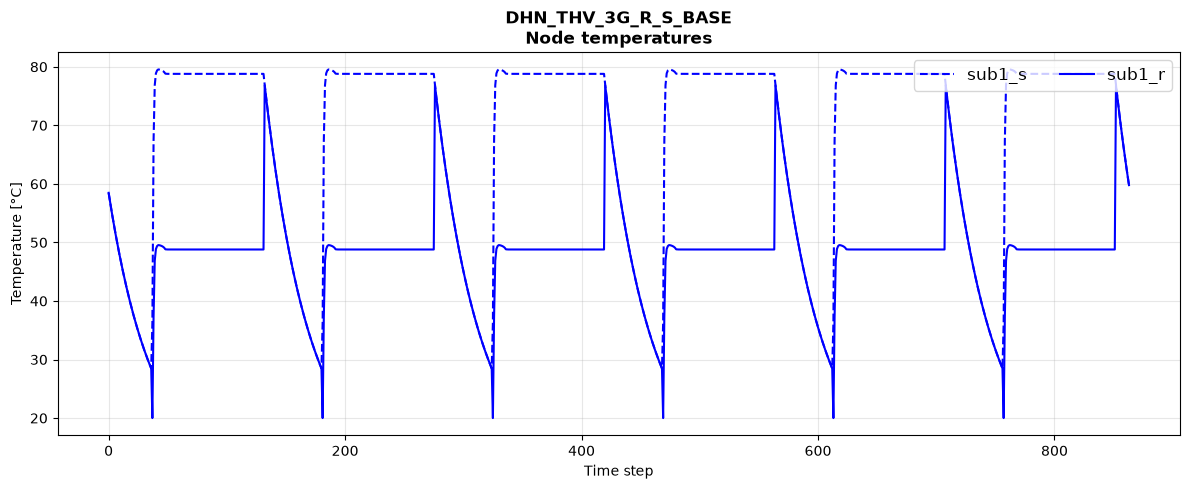

In [99]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(t_nodes["sub1_s"].iloc[144:].values,
        label     = "sub1_s",
        color     = "blue",
        linestyle = "--")
ax.plot(t_nodes["sub1_r"].iloc[144:].values,
        label     = "sub1_r",
        color     = "blue",
        linestyle = "-")

ax.set_xlabel("Time step")
ax.set_ylabel("Temperature [°C]")
ax.set_title("DHN_THV_3G_R_S_BASE\nNode temperatures", fontweight="bold")
ax.legend(loc="upper right", fontsize=12, ncol=2)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

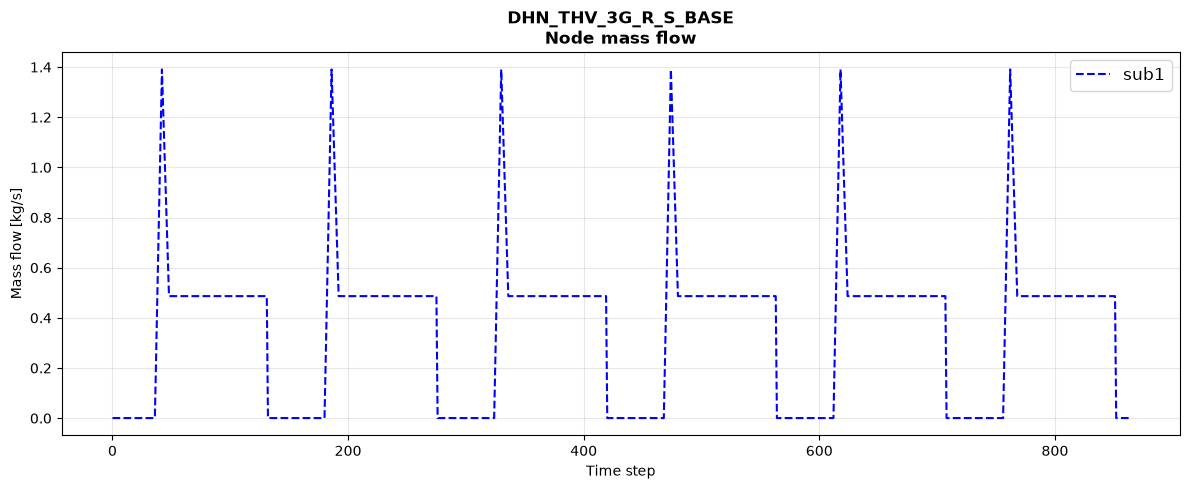

In [101]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(mdot_pipes["sub1"].iloc[144:].values,
        label     = "sub1",
        color     = "blue",
        linestyle = "--")

ax.set_xlabel("Time step")
ax.set_ylabel("Mass flow [kg/s]")
ax.set_title("DHN_THV_3G_R_S_BASE\nNode mass flow", fontweight="bold")
ax.legend(loc="upper right", fontsize=12, ncol=2)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()